# Lab 2: Stochastic Gradient Descent

Welcome to the advanced Machine Learning Course.

The objective of this lab session is to apply stochastic gradient descent on logistic regression.

Please put **"ML - MDS - TD2"** in the mail subject or I might lose your work (which means 0) and send it to ludovic.trautmann@inria.fr

Please label your notebook **"L2_familyname1_familyname2.ipynb"**.

Make sure to put comments in your code. **Raw numerical results or plots without comments will have almost no value in the grading. Please make sure to comment yout results.**

In [77]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np
import pandas as pd
from tqdm import tqdm

We import the dataset that we are going to use, an indian dataset including in the last column information about the diabetes status of patients:

In [123]:
from sklearn import model_selection

data = pd.read_csv("w8a.csv", sep=";", header=None)

X = data.iloc[:,:-1].to_numpy()
y = data.iloc[:,-1].to_numpy()
X = np.hstack([np.ones((X.shape[0], 1)), X])  # Add bias term as we saw in the lecture
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.33, random_state=32)


## Logistic Regression



Today we'll be moving from linear regression to logistic regression, one of the simplest ways to deal with a classification problem. Instead of fitting a line, logistic regression models the probability that the outcome is 1 given the value of the predictor. In order to do this we need a function that transforms our predictor variable to a value between 0 and 1. Lots of functions can do that, but the logistic function is the most common choice:

$$f(z) = \frac{1}{1+\exp{-z}}.$$

To predict the class of our observations we'll have to minimize the corresponding loss function and as we are in a high-dimensional context we'll add an $l_2$ regularization to the model:

$$L(\beta) =1/n  \sum_{i=1}^n log(1+\exp(-y_i\beta^Tx_i))+\frac{\lambda}{2} \| \beta \|^2,$$

where $x_i$ is the vector of features for the observation $i$ and $y_i \in \{-1, 1\}$ is the class label.  


We first use the `sklearn` implementation:

In [79]:
from sklearn.linear_model import LogisticRegression
logistic_regression = LogisticRegression(l1_ratio=0, max_iter=100) # L1 ratio = 0 gives L2 penalty // penalty kwarg is deprecated
logistic_regression.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

and we compute the accuracy score to evaluate the model performance:

In [102]:
from sklearn.metrics import accuracy_score, f1_score
y_pred = logistic_regression.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"F1 score: {f1_score(y_test, y_pred):.4f}")
print(f"Mean of y_test: {np.mean(y_test == -1):.4f}")

Accuracy: 0.9847
F1 score: 0.7136
Mean of y_test: 0.9678


**Comments:** We note the accuracy and F1 values for later use. F1 score will be more relevant for us since we have an imbalanced dataset.

**Comments:** Almost perfect fitting. 

### Assignment

Implement from scratch your own logistic regression model with mini-batch stochastic gradient descent using the Adam optimizer. 

- Fill in the class

- Display the evolution of the cost function along iterations. Do this for several setting of the learning rate

- Train the model with the training set and evaluate its performance in the test set

In [109]:
from sklearn.metrics import roc_auc_score
class StochasticLogisticRegression():
    
    """ Class for logistic regression:
    
    Attributes:                                                                                 
    -----------                                                                              Default value
    coef_         : 1-dimensional np.array, coefficients / weights                         | None                
    lambd_        : float,                  regularization parameter                       | 0.1
    lr_           : float,                  the learning rate                              | 0.01
    bsize         : integer,                the size of the mini-batch >=1                 | 64
    rho           : float,                  rho coefficient (adaptive lr)                  | 0.999
    theta         : float,                  theta coefficient (momentum)                   | 0.9
    eps           : float,                  epsilon coefficient (numerical stability)      | 10-8
    debias        : boolean,                indicates if we use the debiais correction     | False
    coef_history_ : list,                   the list of all visited betas/ weights         | []
    f_history_    : list ,                  the list of all evaluations in visited betas   | []
    thresh        : float,                  decision threshold for classification          | 0.5
    """
    
    def __init__(self, lambd=0.1, lr=1e-2, batchsize=64, rho=0.999, theta=0.9, eps=1e-8, debias=False,
                 thresh=0.5,logging=False):
        self.coef_         = None # weights
        self.lambd_        = lambd
        self.lr_           = lr
        self.bsize_        = batchsize
        self.rho_        = rho
        self.theta_         = theta
        self.eps_          = eps
        self.debias_       = debias
        self.coef_history_ = []
        self.f_history_    = []
        self.thresh_       = thresh
        self.logging_      = logging
    def logistic(self, z):
        return 1/(1+np.exp(-z))
        
    def fit(self, X, y, max_iter=100, minibatch=False):

        """ Fit the data (X, y).
    
        Parameters:
        -----------                                                                         Default value
        X          : (num_samples, num_features) np.array, Design matrix                  | 
        y          : (num_sampes, ) np.array,              Output vector                  |
        max_iter   : integer,                              the number of epochs           | 100
        mini_batch : bool,                                 method used                    | False
        """
        init_weights = np.random.randn(X.shape[1]) * 0.01
        self.f_history_ = []
        self.coef_history_ = [] 
        self.coef_ = init_weights
        self.f1_history_ = []  
        self.auc_history_ = []
        s = np.zeros(X.shape[1])
        m = np.zeros(X.shape[1])
        X_train, X_val, y_train, y_val = model_selection.train_test_split(X, y, test_size=0.33, random_state=32, stratify=y) # We split data to evaluate the model during training
        # stratify is used because the data is unbalanced, we want to keep the same proportion of positive and negative samples in the train and validation sets
        i = 0
        t = 0
     
      
        batch_size = self.bsize_ if minibatch else X_train.shape[0]
        n_batches = X_train.shape[0] // batch_size # Better if X_train.shape[0] % batch_size == 0, otherwise we will not use all the data... 
        while i < max_iter:
            perm = np.random.permutation(X_train.shape[0])
            X_ep = X_train[perm]
            y_ep = y_train[perm]
            j = 0
            i += 1
            while j < n_batches:
                t += 1
                X_batch = X_ep[j*batch_size:(j+1)*batch_size]
                y_batch = y_ep[j*batch_size:(j+1)*batch_size]
                j += 1
                # Compute the gradient for the current batch
                Z = -y_batch[:, None] * X_batch
                grad_log = self.logistic(Z @ self.coef_)
                penalty = self.lambd_ * self.coef_
                penalty[0] = 0  # Bias term is not regularized
                grad = (1 / batch_size) * (Z.T @ grad_log) +  penalty
                # Adam update
                s = self.rho_ * s + (1 - self.rho_) * (grad ** 2)
                m = self.theta_ * m + (1 - self.theta_) * grad
                # Optional debiasing of the estimates
                m_hat = m / (1 - self.theta_ ** t) if self.debias_ else m
                s_hat = s / (1 - self.rho_ ** t) if self.debias_ else s
                self.coef_ = self.coef_ - self.lr_ * m_hat / (np.sqrt(s_hat + self.eps_))
                
            # We chose to evaluate the model on the validation set after each epoch, not after each mini-batch (expensive + for the benchmarks we want to compare the same number of epochs)
            self.coef_history_.append(self.coef_.copy())
            y_val_pred = self.logistic(X_val @ self.coef_)
           
            accuracy = accuracy_score(y_val, np.where(y_val_pred >= 0.5, 1, -1))
            f1 = f1_score(y_val, np.where(y_val_pred >= 0.5, 1, -1))
            loss = np.mean(np.log(1 + np.exp(-y_val * (X_val @ self.coef_)))) + (self.lambd_ / 2) * np.sum(self.coef_[1:] ** 2) # Dont penalize the bias term
            self.f_history_.append([loss, accuracy])
            auc = roc_auc_score(y_val, y_val_pred)
            self.f1_history_.append(f1)
            self.auc_history_.append(auc)
            if self.logging_:
                print(f"Validation loss after epoch {i}: {loss:.4f}")
                print(f"Validation accuracy after epoch {i}: {accuracy:.4f}")
                print(f"Validation AUC after epoch {i}: {auc:.4f}")
        
        best_thresh, best_f1_score = self.find_thresh(X_val, y_val, step=0.01, margin=0)
        self.thresh_ = best_thresh
        if self.logging_:
            print(f"Best threshold found: {best_thresh:.4f} with F1 score: {best_f1_score:.4f}")

            


        
        

    def predict(self, X):
        """ Make binary predictions for data X.
    
        Parameters:
        -----------
        X: (num_samples, num_features) np.array, Design matrix
        
        Returns:
        -----
        y_pred: (num_samples, ) np.array, Predictions (0 or 1)
        """
        #TODO
        y_pred = self.logistic(X@self.coef_)
        return np.where(y_pred >= self.thresh_, 1, -1)
    
    def accuracy_evaluation(self,X,y,thresh=0.5,margin=0.0,vizualisation=True):
        """ Compute detailed accuracy rates.
    
        Parameters:
        -----------                                                              Default value
        X                : (num_samples, num_features) np.array, Input data    | 
        y                : (num_samples, ) np.array, Labels of the input data  | 
        thresh           : Decision threshold                                  | 0.5
        margin           : If the prediction is at a distance less than margin | 0
                           to the treshold, returns undetermined label.        |
        vizualisation    : Allow the user to vizualize in a board the results  | True
            
        Returns:
        -----
        good_prediction  : % of correct classifications
        undetermined     : % of indetermined labels 
        wrong_prediction : % of wrong classifications
        TP               : % of 1 labelled 1
        UP               : % of 1 labelled undetermined
        FN               : % of 1 labelled 0
        TN               : % of 0 labelled 0
        UN               : % of 0 labelled undetermined
        FP               : % of 0 labelled 1
        F1_score         : F1-score
        """ 
       
        y = np.where(y <= 0, 0, 1)
        num_samples = len(y)
        predict = X @ self.coef_
        predict = self.logistic(predict)
        undetermined = np.where((predict < thresh + margin) & (predict > thresh - margin), 1, 0)
        # Undetermined label is -1, 0 is negative class, 1 is positive class
        y_pred = np.where(predict >= thresh + margin, 1, np.where(predict <= thresh - margin, 0, -1))
        good_prediction = np.sum((y_pred == y) & (y_pred != -1)) / num_samples
        undetermined = np.sum(y_pred == -1) / num_samples
        wrong_prediction = np.sum((y_pred != y) & (y_pred != -1)) / num_samples
        TP = np.sum((y_pred == 1) & (y == 1)) / num_samples
        UP = np.sum((y_pred == -1) & (y == 1)) / num_samples
        FN = np.sum((y_pred == 0) & (y == 1)) / num_samples
        TN = np.sum((y_pred == 0) & (y == 0)) / num_samples
        UN = np.sum((y_pred == -1) & (y == 0)) / num_samples
        FP = np.sum((y_pred == 1) & (y == 0)) / num_samples
        F1_score = 2 * TP / (2 * TP + FP + FN) if (2 * TP + FP + FN) > 0 else 0
        if vizualisation:
            display(pd.DataFrame({
                "good_prediction": [good_prediction],
                "undetermined": [undetermined],
                "wrong_prediction": [wrong_prediction],
                "TP": [TP],
                "UP": [UP],
                "FN": [FN],
                "TN": [TN],
                "UN": [UN],
                "FP": [FP],
                "F1_score": [F1_score]
            }))
        return good_prediction, undetermined, wrong_prediction, TP, UP, FN, TN, UN, FP, F1_score

    
    def find_thresh(self, X, y, step=0.01,margin=0):
        """Find the decision threshsold that maximize the f1_score
        
        Parameters:
        -----------                                                    Default value
        X      : (num_samples, num_features) np.array, Input data    | 
        y      : (num_samples, ) np.array, Labels of the input data  | 
        step   : Stepsize between the evaluated thresholds           | 0.01
        margin : If the prediction is at a distance less than margin | 0
                 to the treshold, returns undetermined label.        |
        """  
        
        best_thresh = 0
        best_f1_score = 0
        for thresh in np.arange(0, 1, step):
            _, _, _, TP, UP, FN, TN, UN, FP, F1_score = self.accuracy_evaluation(X,y,thresh=thresh,margin=margin,vizualisation=False)
            if F1_score > best_f1_score:
                best_f1_score = F1_score
                if self.logging_:
                    print(f"New best F1 score: {best_f1_score:.4f} at threshold: {thresh:.4f}")
                best_thresh = thresh
        return best_thresh, best_f1_score

Apply to the data. Use $\lambda = 0.1$ and $lr = 0.01$.

## Training of the model

In [124]:


model = StochasticLogisticRegression(lambd=0.001, lr=0.001)
model.fit(X_train,y_train, minibatch=True, max_iter=30)


Text(0, 0.5, 'F1 Score')

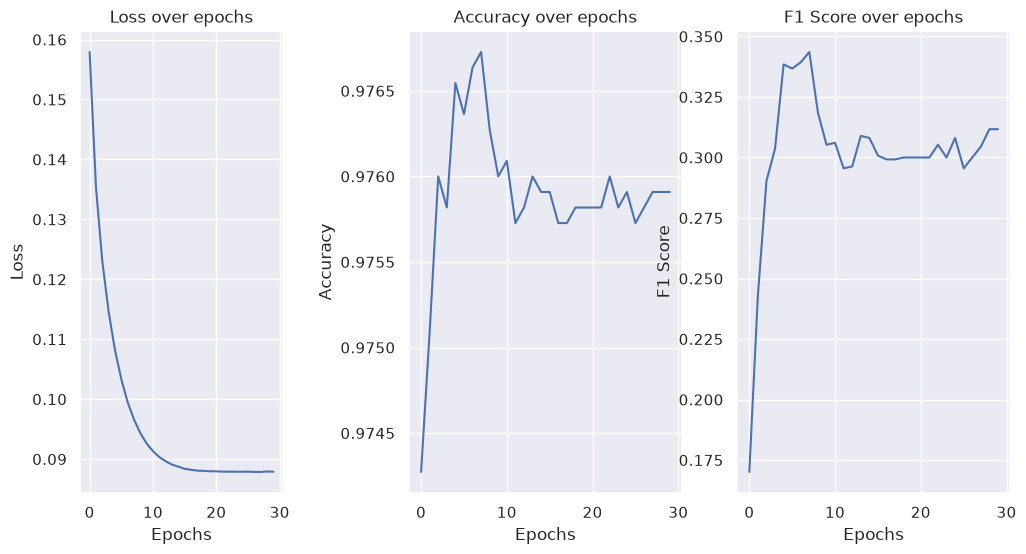

In [111]:
# plot loss, accuracy and f1 score
losses = [loss for loss, _ in model.f_history_]
accuracies = [accuracy for _, accuracy in model.f_history_]
f1_scores = model.f1_history_
auc_scores = model.auc_history_



plt.figure(figsize=(12, 6))
plt.subplot(1, 4, 1)
plt.plot(losses, label='Loss')
plt.title('Loss over epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.subplot(1, 3, 2)
plt.plot(accuracies, label='Accuracy')
plt.title('Accuracy over epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.subplot(1, 3, 3)
plt.plot(f1_scores, label='F1 Score')
plt.title('F1 Score over epochs')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')


We see here that the loss is indeed decreasing, the accuracy is barely moving and the F1 is increasing and 

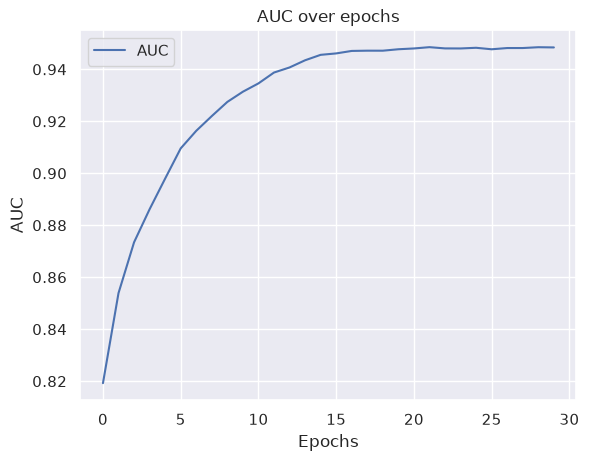

In [121]:
plt.plot(auc_scores, label='AUC')
plt.title('AUC over epochs')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.legend()


The AUC accross epochs goes around 95%: our model learns how to classify the binary data.

In [126]:
y_pred = model.predict(X_test)
accuracy_score(y_test, y_pred)

0.9760628578389572

In [125]:
good_prediction, undetermined, wrong_prediction, TP, UP, FN, TN, UN, FP, F1_score = model.accuracy_evaluation(X_test,y_test,thresh=model.thresh_,margin=0,vizualisation=True)
print(f"Good prediction: {good_prediction:.4f}, Undetermined: {undetermined:.4f}, Wrong prediction: {wrong_prediction:.4f}")
print(f"TP: {TP:.4f}, UP: {UP:.4f}, FN: {FN:.4f}, TN: {TN:.4f}, UN: {UN:.4f}, FP: {FP:.4f}, F1 score: {F1_score:.4f}")
print(f"Mean of y_test == 1: {np.mean(y_test == 1):.4f}, Mean of y_test == -1: {np.mean(y_test == -1):.4f}")
print(f"Mean of model.predict(X_test) == 1: {np.mean(model.predict(X_test) == 1):.4f}")
print(f"Mean of y_test: {np.mean(y_test == 1):.4f}")

,good_prediction,undetermined,wrong_prediction,TP,UP,FN,TN,UN,FP,F1_score
0,0.976063,0.0,0.023937,0.020039,0.0,0.012486,0.956024,0.0,0.011451,0.62607


Good prediction: 0.9761, Undetermined: 0.0000, Wrong prediction: 0.0239
TP: 0.0200, UP: 0.0000, FN: 0.0125, TN: 0.9560, UN: 0.0000, FP: 0.0115, F1 score: 0.6261
Mean of y_test == 1: 0.0325, Mean of y_test == -1: 0.9675
Mean of model.predict(X_test) == 1: 0.0315
Mean of y_test: 0.0325


We see here that even if the TP is very low, this is still correct as the mean of y_test is close to 0.03 => very few positive samples in the test set. F1 score is close to 65%, almost reaching the baseline value of scikit learn classifier.

**Comments:** Playing with multiple margins, we of course have 0 undetermined if margin = 0 (hopefully), and the number of undetermined grows with the margin...

## Optimal threshold

In [87]:
#TODO
# The optimal threshold has already been found during training phase.
print(f"Optimal threshold found during training: {model.thresh_:.4f}")

Optimal threshold found during training: 0.1200


## Study of the batchsize impact

[[np.float64(0.1476234756595978), 0.9716363636363636], [np.float64(0.12055750092538628), 0.9716363636363636], [np.float64(0.11542376085541557), 0.9716363636363636], [np.float64(0.11456199141970219), 0.9716363636363636], [np.float64(0.11431475459764784), 0.9716363636363636], [np.float64(0.11423569919940281), 0.9716363636363636], [np.float64(0.11420058679038152), 0.9716363636363636], [np.float64(0.11445071934977463), 0.9716363636363636], [np.float64(0.11415440511935648), 0.9716363636363636], [np.float64(0.11436055619446664), 0.9716363636363636], [np.float64(0.11432594653711602), 0.9716363636363636], [np.float64(0.11430669719074758), 0.9716363636363636], [np.float64(0.11423281830322021), 0.9716363636363636], [np.float64(0.11412527911232487), 0.9716363636363636], [np.float64(0.11417148070062327), 0.9716363636363636], [np.float64(0.11435334112130044), 0.9716363636363636], [np.float64(0.11410976671206485), 0.9716363636363636], [np.float64(0.11403679699382836), 0.9716363636363636], [np.float6

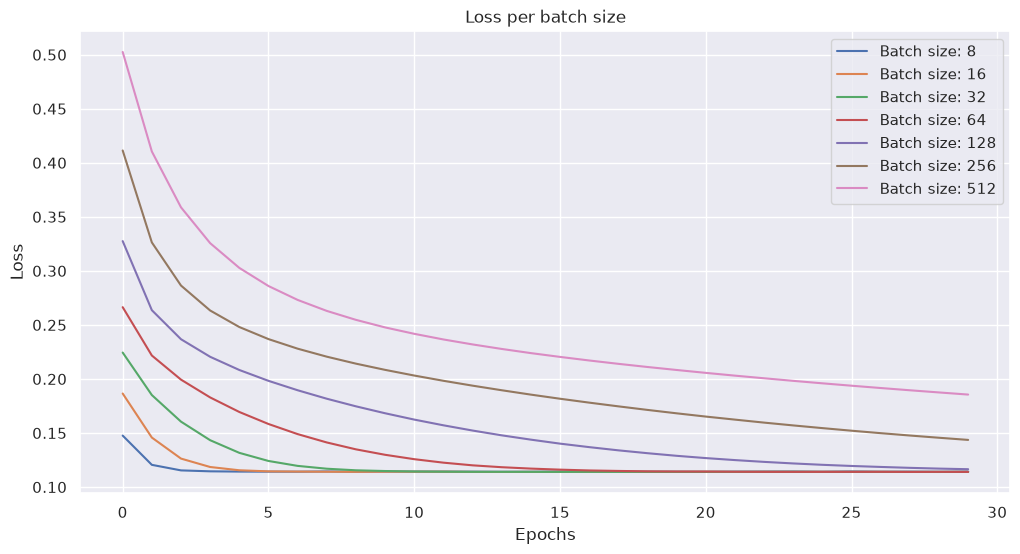

In [88]:
#TODO : Study the loss
batch_sizes = [8, 16, 32, 64, 128, 256, 512]
losses_per_batch_size = {}
accuracies_per_batch_size = {}
f1_per_batch_size = {}
auc_per_batch_size = {}
for batch_size in batch_sizes:
    model = StochasticLogisticRegression(lambd=0.01, lr=0.001, batchsize=batch_size, debias=True)
    model.fit(X_train,y_train, minibatch=True, max_iter=30)
    print(model.f_history_)
    losses_per_batch_size[batch_size] = [loss for loss, _ in model.f_history_]
    f1_per_batch_size[batch_size] = model.f1_history_
    auc_per_batch_size[batch_size] = model.auc_history_
    accuracies_per_batch_size[batch_size] = [accuracy for _, accuracy in model.f_history_]

plt.figure(figsize=(12, 6))
for batch_size in batch_sizes:
    plt.plot(losses_per_batch_size[batch_size], label=f'Batch size: {batch_size}')
plt.title('Loss per batch size')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

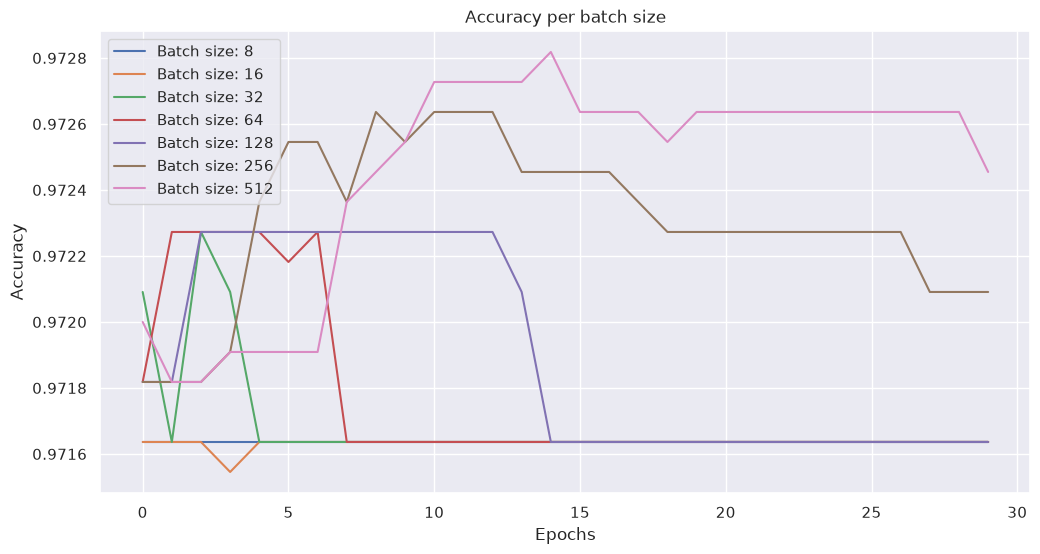

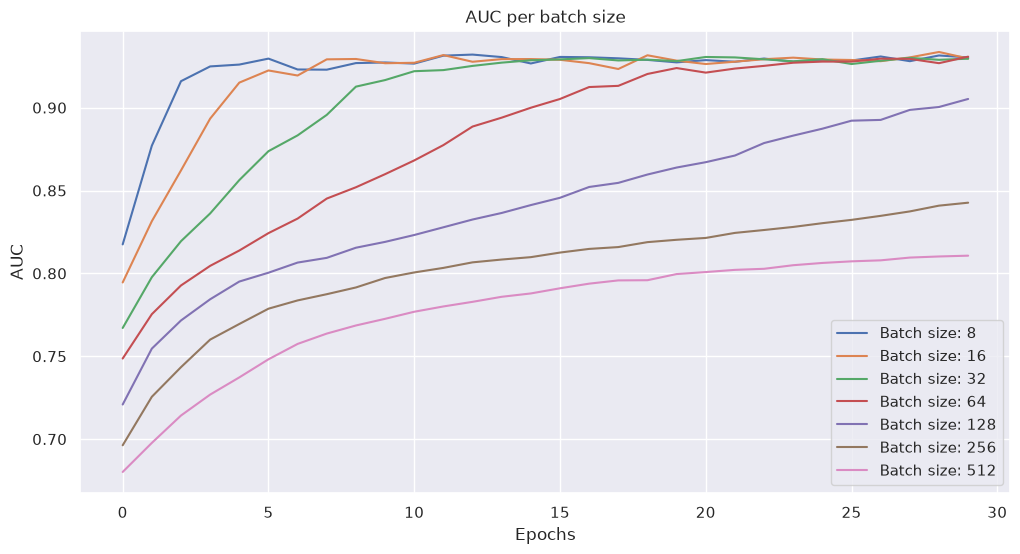

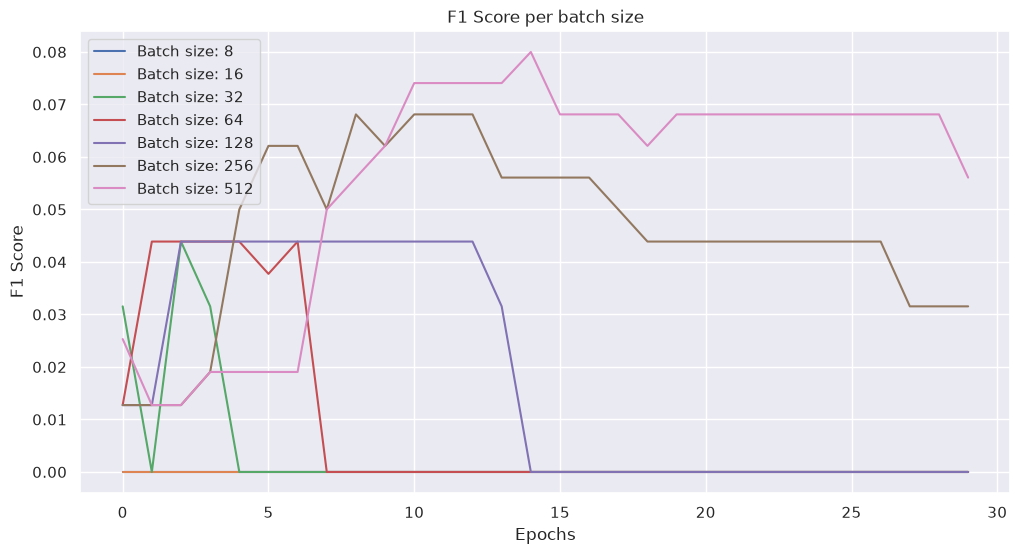

In [89]:
#TODO : Study the accuracy
plt.figure(figsize=(12, 6))
for batch_size in batch_sizes:
    plt.plot(accuracies_per_batch_size[batch_size], label=f'Batch size: {batch_size}')
plt.title('Accuracy per batch size')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.figure(figsize=(12, 6))
for batch_size in batch_sizes:
    plt.plot(auc_per_batch_size[batch_size], label=f'Batch size: {batch_size}')
plt.title('AUC per batch size')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.legend()

plt.figure(figsize=(12, 6))
for batch_size in batch_sizes:
    plt.plot(f1_per_batch_size[batch_size], label=f'Batch size: {batch_size}')
plt.title('F1 Score per batch size')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()

## rho impact

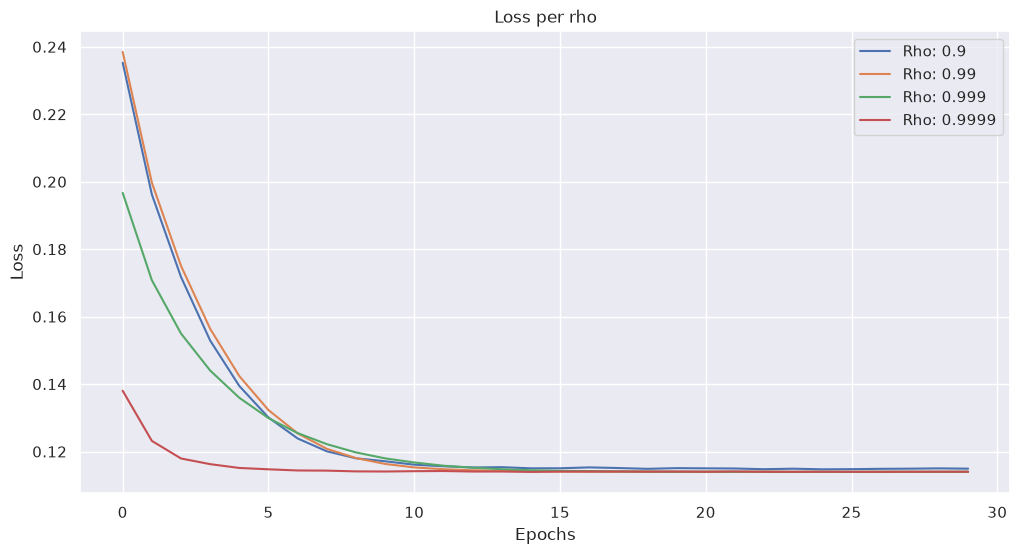

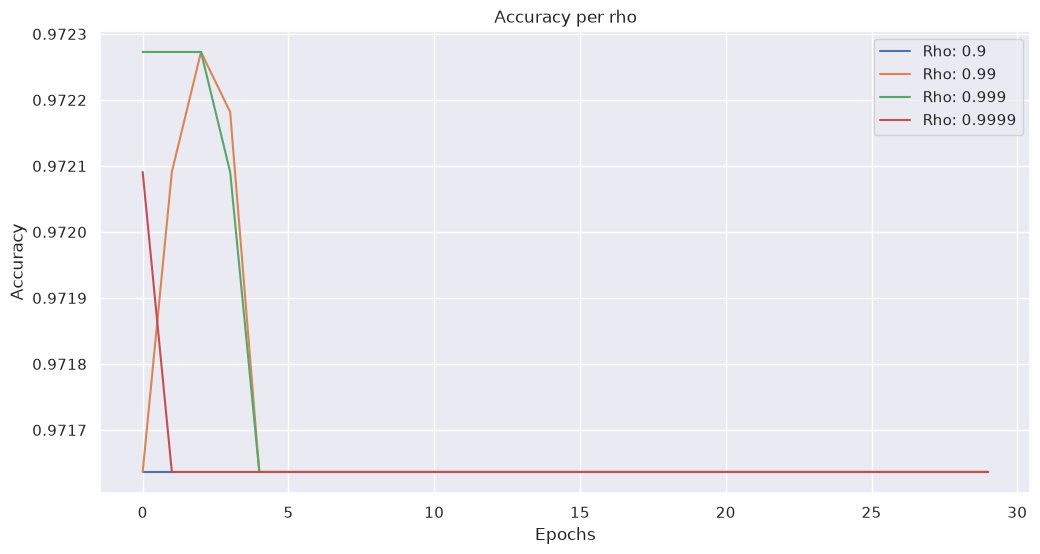

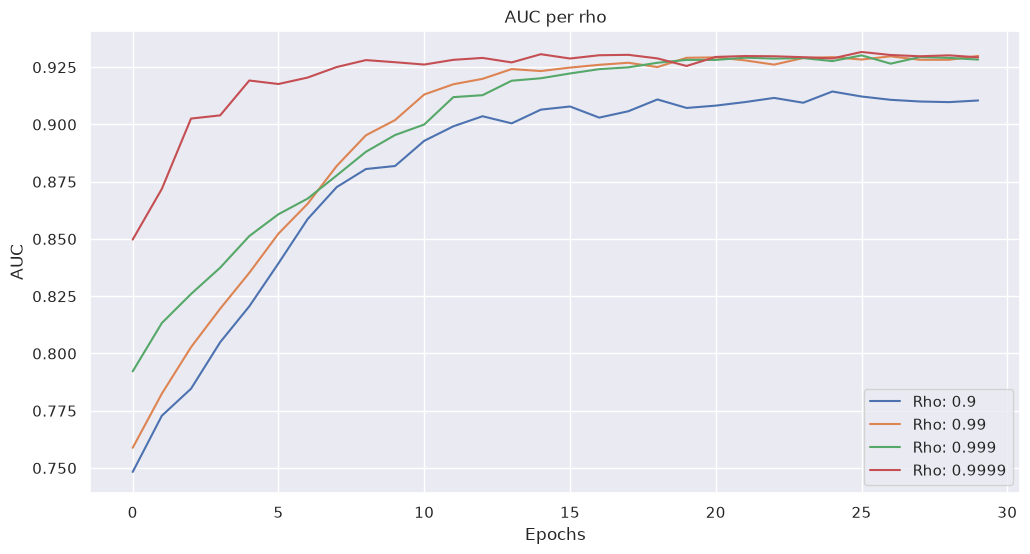

In [90]:
#TODO : Study Loss and F1-score
rhos = [0.9, 0.99, 0.999, 0.9999]
losses_per_rho = {}
accuracies_per_rho = {}
auc_per_rho = {}
for rho in rhos:
    model = StochasticLogisticRegression(lambd=0.01, lr=0.001, rho=rho)
    model.fit(X_train,y_train, minibatch=True, max_iter=30)
    losses_per_rho[rho] = [loss for loss, _ in model.f_history_]
    accuracies_per_rho[rho] = [accuracy for _, accuracy in model.f_history_]
    auc_per_rho[rho] = model.auc_history_

plt.figure(figsize=(12, 6))
for rho in rhos:
    plt.plot(losses_per_rho[rho], label=f'Rho: {rho}')
plt.title('Loss per rho')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.figure(figsize=(12, 6))
for rho in rhos:
    plt.plot(accuracies_per_rho[rho], label=f'Rho: {rho}')
plt.title('Accuracy per rho')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.figure(figsize=(12, 6))
for rho in rhos:
    plt.plot(auc_per_rho[rho], label=f'Rho: {rho}')
plt.title('AUC per rho')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.legend()

## theta impact

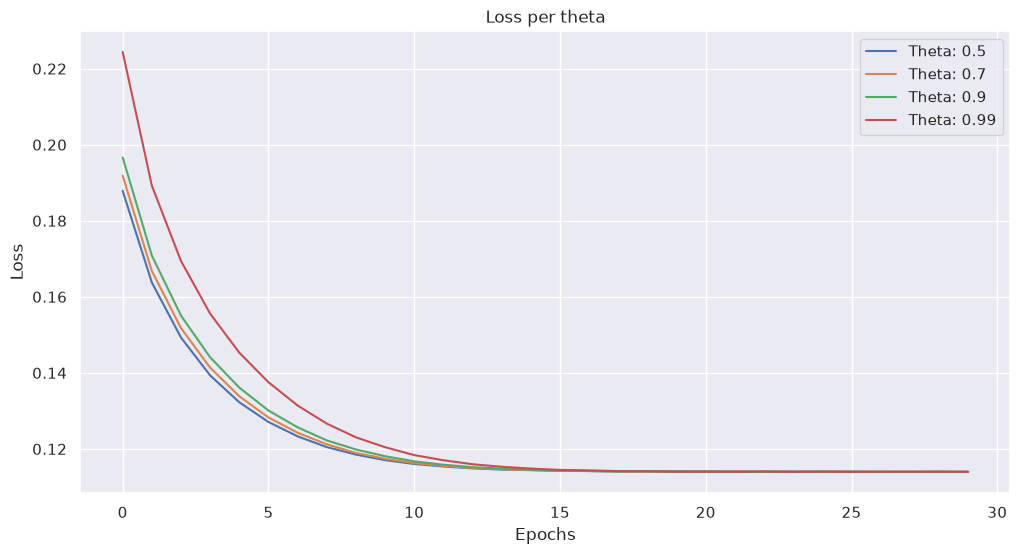

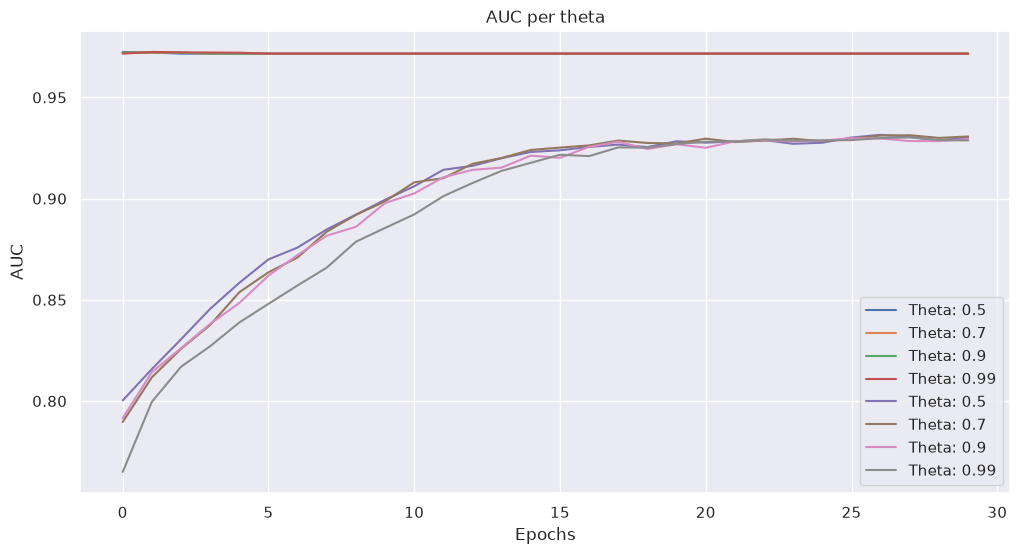

In [91]:
#TODO : Study Loss and F1-score
thetas = [0.5, 0.7, 0.9, 0.99]
losses_per_theta = {}
accuracies_per_theta = {}
auc_per_theta = {}
for theta in thetas:
    model = StochasticLogisticRegression(lambd=0.01, lr=0.001, theta=theta)
    model.fit(X_train,y_train, minibatch=True, max_iter=30)
    losses_per_theta[theta] = [loss for loss, _ in model.f_history_]
    accuracies_per_theta[theta] = [accuracy for _, accuracy in model.f_history_]
    auc_per_theta[theta] = model.auc_history_
plt.figure(figsize=(12, 6))
for theta in thetas:
    plt.plot(losses_per_theta[theta], label=f'Theta: {theta}')
plt.title('Loss per theta')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.figure(figsize=(12, 6))
for theta in thetas:
    plt.plot(accuracies_per_theta[theta], label=f'Theta: {theta}')
plt.title('Accuracy per theta')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

for theta in thetas:
    plt.plot(auc_per_theta[theta], label=f'Theta: {theta}')
plt.title('AUC per theta')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.legend()